# Phase 2 — MovieLens Data Preprocessing & Temporal Splitting

## Objectives
- Validate MovieLens Latest Small.
- Generate user, movie and genre mappings.
- Label positive interactions (rating >= 4.0).
- Perform global temporal splitting (80/10/10).
- Validate chronological integrity and prevent data leakage.
- Save processed datasets and split metadata.

**Execution environment:** Windows 11, VS Code, Python virtual environment (.venv).

**Scope:** Data preprocessing only. No graph construction or model training.

Import và cấu hình đường dẫn

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "src" / "data").is_dir():
            return candidate

    raise FileNotFoundError(
        "Cannot find project root. Open the repository in VS Code."
    )

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-latest-small"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)
print("Dataset exists:", RAW_DIR.exists())

Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
Dataset exists: True


Kiểm tra dữ liệu gốc

In [2]:
ratings_path = RAW_DIR / "ratings.csv"
movies_path = RAW_DIR / "movies.csv"

assert ratings_path.exists(), "Missing ratings.csv"
assert movies_path.exists(), "Missing movies.csv"

ratings = pd.read_csv(ratings_path)
movies = pd.read_csv(movies_path)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

display(ratings.head())
display(movies.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Chạy pipeline Phase 2

In [3]:
from src.data.preprocessing import run_pipeline

metadata = run_pipeline(
    raw_dir=RAW_DIR,
    output_root=PROJECT_ROOT / "data"
)

print("Phase 2 pipeline completed.")
display(pd.DataFrame(
    metadata.items(),
    columns=["Metric", "Value"]
))

Phase 2 pipeline completed.


,Metric,Value
0,dataset,MovieLens Latest Small
1,split_method,global_temporal
2,timestamp_tie_policy,keep_together
3,train_ratio_target,0.8
4,val_ratio_target,0.1
5,test_ratio_target,0.1
6,positive_threshold,4.0
7,seed,42
8,num_users,610
9,num_movies,9742


Đọc dữ liệu sau xử lý

In [4]:
interactions = pd.read_csv(
    PROCESSED_DIR / "interactions.csv"
)

train = pd.read_csv(SPLITS_DIR / "train.csv")
val = pd.read_csv(SPLITS_DIR / "val.csv")
test = pd.read_csv(SPLITS_DIR / "test.csv")

print("Total interactions:", len(interactions))
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

display(interactions.head(10))

Total interactions: 100836
Train: 80669
Validation: 10083
Test: 10084


,interaction_id,userId,movieId,rating,timestamp,user_idx,movie_idx,is_positive
0,0,429,22,4.0,828124615,428,21,1
1,1,429,150,5.0,828124615,428,123,1
2,2,429,161,5.0,828124615,428,134,1
3,3,429,165,4.0,828124615,428,138,1
4,4,429,218,4.0,828124615,428,186,1
5,5,429,222,4.0,828124615,428,189,1
6,6,429,225,4.0,828124615,428,192,1
7,7,429,227,3.0,828124615,428,193,0
8,8,429,343,3.0,828124615,428,301,0
9,9,429,349,3.0,828124615,428,307,0


Thống kê phân chia dữ liệu

In [5]:
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Interactions": [
        len(train), len(val), len(test)
    ],
    "Positive": [
        int(train["is_positive"].sum()),
        int(val["is_positive"].sum()),
        int(test["is_positive"].sum())
    ]
})

split_summary["Ratio (%)"] = (
    split_summary["Interactions"]
    / len(interactions) * 100
)

split_summary["Positive Ratio (%)"] = (
    split_summary["Positive"]
    / split_summary["Interactions"] * 100
)

display(split_summary.round(2))

,Split,Interactions,Positive,Ratio (%),Positive Ratio (%)
0,Train,80669,39255,80.0,48.66
1,Validation,10083,5197,10.0,51.54
2,Test,10084,4128,10.0,40.94


Biểu đồ Temporal Split

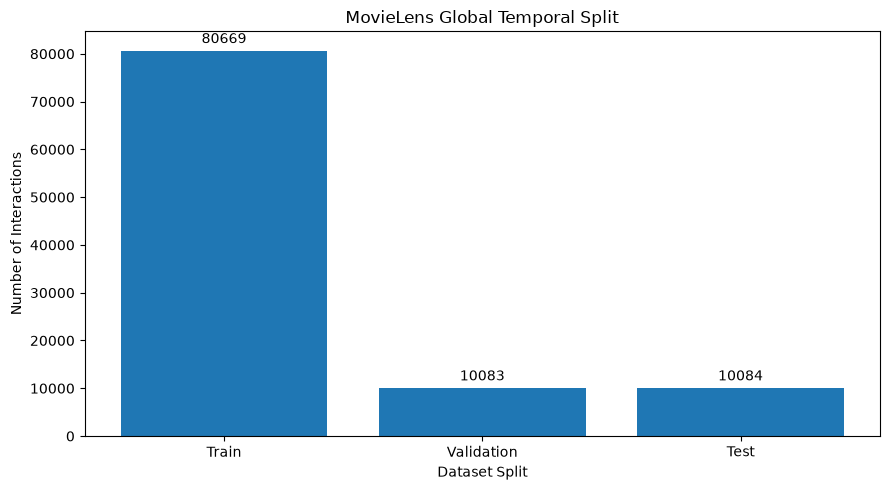

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    split_summary["Split"],
    split_summary["Interactions"]
)

ax.bar_label(bars, padding=3)
ax.set_title("MovieLens Global Temporal Split")
ax.set_ylabel("Number of Interactions")
ax.set_xlabel("Dataset Split")

plt.tight_layout()
plt.show()

Kiểm tra thứ tự thời gian

In [7]:
temporal_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Start Timestamp": [
        train["timestamp"].min(),
        val["timestamp"].min(),
        test["timestamp"].min()
    ],
    "End Timestamp": [
        train["timestamp"].max(),
        val["timestamp"].max(),
        test["timestamp"].max()
    ]
})

temporal_summary["Start Date"] = pd.to_datetime(
    temporal_summary["Start Timestamp"],
    unit="s",
    utc=True
)

temporal_summary["End Date"] = pd.to_datetime(
    temporal_summary["End Timestamp"],
    unit="s",
    utc=True
)

display(temporal_summary)

assert train["timestamp"].max() < val["timestamp"].min()
assert val["timestamp"].max() < test["timestamp"].min()

print("Temporal ordering: PASSED")

,Split,Start Timestamp,End Timestamp,Start Date,End Date
0,Train,828124615,1458635171,1996-03-29 18:36:55+00:00,2016-03-22 08:26:11+00:00
1,Validation,1458635237,1498029445,2016-03-22 08:27:17+00:00,2017-06-21 07:17:25+00:00
2,Test,1498029450,1537799250,2017-06-21 07:17:30+00:00,2018-09-24 14:27:30+00:00


Temporal ordering: PASSED


Kiểm tra tính toàn vẹn và data leakage

In [8]:
from src.data.preprocessing import validate_splits

validate_splits(
    train,
    val,
    test,
    interactions
)

all_ids = pd.concat([
    train["interaction_id"],
    val["interaction_id"],
    test["interaction_id"]
])

assert all_ids.is_unique
assert len(all_ids) == len(interactions)

assert set(all_ids) == set(interactions["interaction_id"])

print("No duplicate interaction IDs: PASSED")
print("No missing interactions: PASSED")
print("No cross-split timestamp overlap: PASSED")

No duplicate interaction IDs: PASSED
No missing interactions: PASSED
No cross-split timestamp overlap: PASSED


Kiểm tra User/Movie/Genre Mapping

In [9]:
user_mapping = pd.read_csv(
    PROCESSED_DIR / "user_mapping.csv"
)

movie_mapping = pd.read_csv(
    PROCESSED_DIR / "movie_mapping.csv"
)

genre_mapping = pd.read_csv(
    PROCESSED_DIR / "genre_mapping.csv"
)

movie_genres = pd.read_csv(
    PROCESSED_DIR / "movie_genres.csv"
)

mapping_summary = pd.DataFrame({
    "Entity": ["User", "Movie", "Genre", "Movie-Genre Edges"],
    "Count": [
        len(user_mapping),
        len(movie_mapping),
        len(genre_mapping),
        len(movie_genres)
    ]
})

display(mapping_summary)

assert user_mapping["user_idx"].is_unique
assert movie_mapping["movie_idx"].is_unique
assert genre_mapping["genre_idx"].is_unique

assert interactions["user_idx"].isin(
    user_mapping["user_idx"]
).all()

assert interactions["movie_idx"].isin(
    movie_mapping["movie_idx"]
).all()

print("Mapping integrity: PASSED")

,Entity,Count
0,User,610
1,Movie,9742
2,Genre,19
3,Movie-Genre Edges,22050


Mapping integrity: PASSED


Kiểm tra Evaluation Users

In [10]:
evaluation_users = pd.read_csv(
    SPLITS_DIR / "evaluation_users.csv"
)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Eligible Validation Users",
        "Eligible Test Users"
    ],
    "Count": [
        len(evaluation_users),
        int(evaluation_users["eligible_val"].sum()),
        int(evaluation_users["eligible_test"].sum())
    ]
})

display(evaluation_summary)

assert evaluation_users["user_idx"].is_unique

print("Evaluation user eligibility: PASSED")

,Metric,Count
0,Total Users,610
1,Eligible Validation Users,21
2,Eligible Test Users,25


Evaluation user eligibility: PASSED


Chạy Unit Tests

In [11]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-p",
        "test_preprocessing.py",
        "-v"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, "Unit tests failed"

print("All Phase 2 tests: PASSED")


test_all_interactions_preserved (test_preprocessing.TestPreprocessing.test_all_interactions_preserved) ... ok
test_evaluation_user_flags (test_preprocessing.TestPreprocessing.test_evaluation_user_flags) ... ok
test_mapping_is_unique (test_preprocessing.TestPreprocessing.test_mapping_is_unique) ... ok
test_no_overlap (test_preprocessing.TestPreprocessing.test_no_overlap) ... ok
test_positive_threshold (test_preprocessing.TestPreprocessing.test_positive_threshold) ... ok
test_temporal_order (test_preprocessing.TestPreprocessing.test_temporal_order) ... ok
test_timestamp_ties_not_split (test_preprocessing.TestPreprocessing.test_timestamp_ties_not_split) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.141s

OK

All Phase 2 tests: PASSED


Lưu báo cáo Phase 2

In [12]:
REPORT_DIR = PROJECT_ROOT / "experiments" / "phase2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = {
    "phase": 2,
    "dataset": "MovieLens Latest Small",
    "execution": "local",
    "num_interactions": len(interactions),
    "train_count": len(train),
    "val_count": len(val),
    "test_count": len(test),
    "train_positive": int(train["is_positive"].sum()),
    "val_positive": int(val["is_positive"].sum()),
    "test_positive": int(test["is_positive"].sum()),
    "eligible_val_users": int(
        evaluation_users["eligible_val"].sum()
    ),
    "eligible_test_users": int(
        evaluation_users["eligible_test"].sum()
    ),
    "temporal_integrity": "passed",
    "unit_tests": "passed"
}

report_path = REPORT_DIR / "phase2_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("Report saved:", report_path)

Report saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase2\phase2_report.json
